# Notebook 4 — Inferencia Masiva y Exportacion

Usa el modelo entrenado para clasificar todos los segmentos de la biblioteca.

**No modifica los MP3 originales.** El resultado es:
- `C:\temporales\clasificacion_final.xlsx` — con hoja de resumen e indefinidos
- `C:\temporales\clasificacion_final.csv`

In [1]:
# CELDA 1 — CONFIGURACION
import os
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

METADATA_PATH = r"C:\temporales\metadata.csv"
MODEL_PATH    = r"C:\temporales\modelos\clasificador_radio_v1.pth"
OUTPUT_XLSX   = r"C:\temporales\clasificacion_final.xlsx"
OUTPUT_CSV    = r"C:\temporales\clasificacion_final.csv"

BATCH_SIZE    = 256
# Windows+Jupyter no soporta num_workers > 0 en DataLoader (usa spawn)
NUM_WORKERS   = 0 if platform.system() == 'Windows' else 6

# Segmentos con confianza < MIN_CONFIDENCE -> 'indefinido'
MIN_CONFIDENCE = 0.50

# False = respetar etiquetas humanas (recomendado)
SOBREESCRIBIR_HUMANOS = False

print("Configuracion lista")
print(f"  num_workers = {NUM_WORKERS} ({'Windows: carga en hilo principal' if NUM_WORKERS == 0 else 'multiprocessing'})")


Configuracion lista
  num_workers = 0 (Windows: carga en hilo principal)


In [2]:
# CELDA 2 — CARGAR MODELO
import torch
import torchaudio
import torchaudio.transforms as T
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast
import timm
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")
if device.type == 'cuda':
    print(f"  GPU: {torch.cuda.get_device_name(0)}")

checkpoint   = torch.load(MODEL_PATH, map_location=device)
LABEL_TO_IDX = checkpoint['label_to_idx']
IDX_TO_LABEL = checkpoint['idx_to_label']
cfg          = checkpoint['config']
N_CLASES     = len(LABEL_TO_IDX)

SAMPLE_RATE = cfg['sample_rate']; N_MELS = cfg['n_mels']
N_FFT       = cfg['n_fft']; HOP_LENGTH = cfg['hop_length']
IMG_SIZE    = cfg['img_size']

model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=N_CLASES)
model.load_state_dict(checkpoint['model_state'])
model = model.to(device); model.eval()

print(f"Modelo cargado (epoca {checkpoint['epoch']}) | Clases: {list(LABEL_TO_IDX.keys())}")


Dispositivo: cuda
  GPU: NVIDIA GeForce RTX 3090
Modelo cargado (epoca 49) | Clases: ['deportes', 'entrevistas', 'locutor', 'musica']


In [3]:
# CELDA 3 — DATASET DE INFERENCIA
class InferenceDataset(Dataset):
    def __init__(self, wav_paths):
        self.paths = wav_paths
        self.mel_t = T.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT,
            hop_length=HOP_LENGTH, n_mels=N_MELS, f_max=15000)
        self.db_t = T.AmplitudeToDB(top_db=80)

    def __len__(self): return len(self.paths)

    def __getitem__(self, idx):
        try:
            wf, sr = torchaudio.load(self.paths[idx])
            if sr != SAMPLE_RATE: wf = T.Resample(sr, SAMPLE_RATE)(wf)
            if wf.shape[0] > 1:  wf = wf.mean(dim=0, keepdim=True)
            mel = self.db_t(self.mel_t(wf))
            mn, mx = mel.min(), mel.max()
            if mx > mn: mel = 2.0 * (mel - mn) / (mx - mn) - 1.0
            mel_r = torch.nn.functional.interpolate(
                mel.unsqueeze(0), size=(IMG_SIZE, IMG_SIZE),
                mode='bilinear', align_corners=False).squeeze(0)
            return mel_r.repeat(3, 1, 1)
        except Exception:
            return torch.zeros(3, IMG_SIZE, IMG_SIZE)

print("Dataset de inferencia definido")


Dataset de inferencia definido


In [4]:
# CELDA 4 — PREPARAR SEGMENTOS A CLASIFICAR
df = pd.read_csv(METADATA_PATH)
to_classify = (df.copy() if SOBREESCRIBIR_HUMANOS
               else df[df['label_fuente'] != 'humano'].copy())
to_classify = to_classify[
    to_classify['ruta_wav'].apply(lambda p: Path(p).exists())
].reset_index(drop=True)

print(f"Total en metadata         : {len(df):,}")
print(f"Etiquetados por humano    : {(df['label_fuente'] == 'humano').sum():,}")
print(f"A clasificar con el modelo: {len(to_classify):,}")


Total en metadata         : 46,471
Etiquetados por humano    : 126
A clasificar con el modelo: 46,345


In [5]:
# CELDA 5 — INFERENCIA MASIVA EN GPU
from tqdm.notebook import tqdm

inf_ds = InferenceDataset(to_classify['ruta_wav'].tolist())
inf_loader = DataLoader(inf_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)

all_labels, all_confs, all_probs = [], [], []

print(f"Procesando {len(to_classify):,} segmentos en batches de {BATCH_SIZE}...")
with torch.no_grad():
    for batch in tqdm(inf_loader, desc="Clasificando", unit="batch"):
        batch = batch.to(device, non_blocking=True)
        with autocast():
            logits = model(batch)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        all_labels.extend([IDX_TO_LABEL[i] for i in probs.argmax(axis=1)])
        all_confs.extend(probs.max(axis=1).tolist())
        all_probs.extend(probs.tolist())

final_labels = [l if c >= MIN_CONFIDENCE else 'indefinido'
                for l, c in zip(all_labels, all_confs)]

to_classify['label_modelo']     = final_labels
to_classify['confianza_modelo'] = all_confs
print("Inferencia completa")


Procesando 46,345 segmentos en batches de 256...


Clasificando:   0%|          | 0/182 [00:00<?, ?batch/s]

Inferencia completa


In [9]:
# CELDA 6 — CONSTRUIR TABLA FINAL Y EXPORTAR
cols_base = ['segment_id', 'archivo_origen', 'inicio_ms', 'fin_ms', 'duracion_s', 'ruta_wav']

df_humanos = df[df['label_fuente'] == 'humano'][cols_base].copy()
df_humanos['label'] = df[df['label_fuente'] == 'humano']['label'].values
df_humanos['confianza'] = 1.0; df_humanos['fuente'] = 'humano'

df_modelo = to_classify[cols_base].copy()
df_modelo['label']    = to_classify['label_modelo'].values
df_modelo['confianza'] = to_classify['confianza_modelo'].values
df_modelo['fuente']   = 'modelo'
for i, cat in enumerate(sorted(LABEL_TO_IDX.keys())):
    df_modelo[f'prob_{cat}'] = [p[LABEL_TO_IDX[cat]] for p in all_probs]

df_final = pd.concat([df_humanos, df_modelo], ignore_index=True)
df_final  = df_final.sort_values(['archivo_origen', 'inicio_ms'])

print(f"Total clasificado: {len(df_final):,} segmentos")
print(df_final.groupby('label').size().sort_values(ascending=False).to_frame('cantidad'))

df_final.to_csv(OUTPUT_CSV, index=False, encoding='utf-8-sig')
print(f"CSV exportado: {OUTPUT_CSV}")

resumen = df_final.groupby('label').agg(
    cantidad=('segment_id', 'count'),
    duracion_horas=('duracion_s', lambda x: round(x.sum()/3600, 2)),
    confianza_prom=('confianza', lambda x: round(x.mean(), 3))
).reset_index().sort_values('cantidad', ascending=False)

indef = df_final[df_final['label'] == 'indefinido']

with pd.ExcelWriter(OUTPUT_XLSX, engine='openpyxl') as w:
    df_final.to_excel(w, sheet_name='Clasificacion', index=False)
    resumen.to_excel(w, sheet_name='Resumen', index=False)
    indef.to_excel(w, sheet_name='Indefinidos', index=False)
print(f"Excel exportado: {OUTPUT_XLSX}")


Total clasificado: 46,471 segmentos
             cantidad
label                
locutor         27581
musica          16534
indefinido       2328
entrevistas        20
deportes            8
CSV exportado: C:\temporales\clasificacion_final.csv
Excel exportado: C:\temporales\clasificacion_final.xlsx


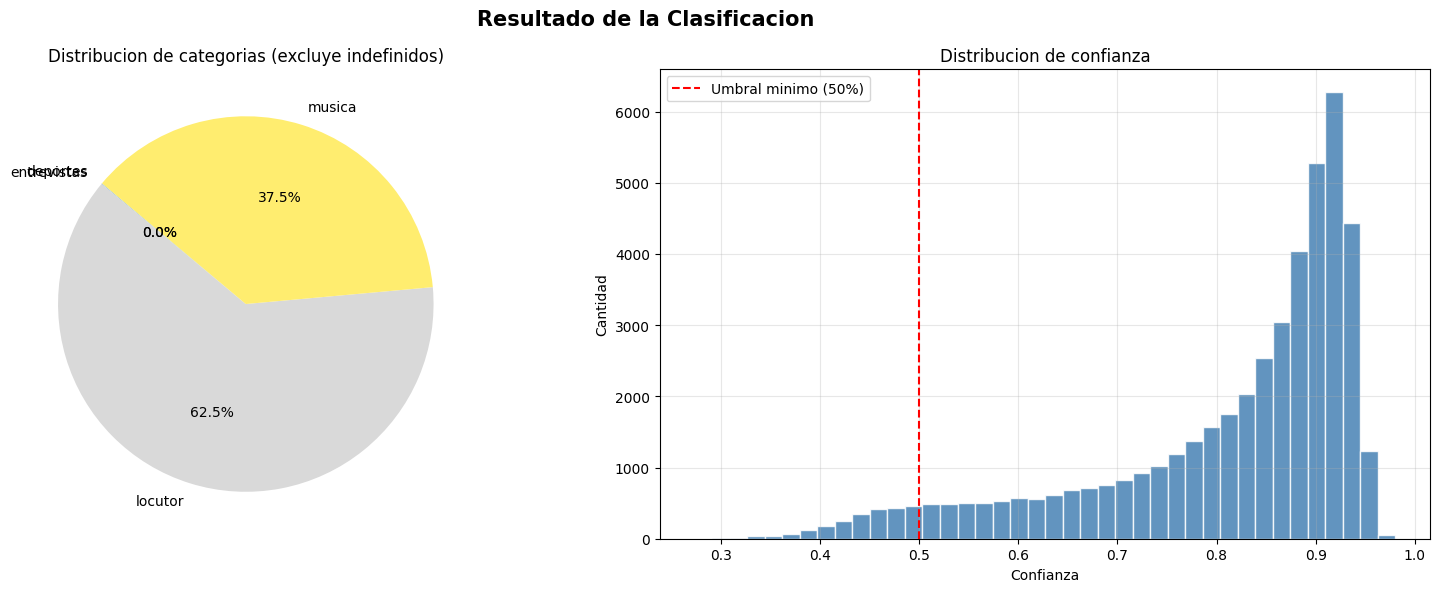

Proceso completo!
  Total clasificado     : 46,471
  Confianza alta (>80%) : 31,202
  Indefinidos           : 2,328


In [10]:
# CELDA 7 — GRAFICOS DE RESULTADO
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Resultado de la Clasificacion", fontsize=15, fontweight='bold')

dist_plot = df_final[df_final['label'] != 'indefinido'].groupby('label').size()
colors = plt.cm.Set3(np.linspace(0, 1, len(dist_plot)))
axes[0].pie(dist_plot.values, labels=dist_plot.index,
            autopct='%1.1f%%', colors=colors, startangle=140)
axes[0].set_title("Distribucion de categorias (excluye indefinidos)")

axes[1].hist(df_final[df_final['fuente'] == 'modelo']['confianza'],
             bins=40, color='steelblue', edgecolor='white', alpha=0.85)
axes[1].axvline(x=MIN_CONFIDENCE, color='red', linestyle='--',
               label=f'Umbral minimo ({MIN_CONFIDENCE:.0%})')
axes[1].set_title("Distribucion de confianza")
axes[1].set_xlabel("Confianza"); axes[1].set_ylabel("Cantidad")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(r"C:\temporales\resultado.png", dpi=120, bbox_inches='tight')
plt.show()

print(f"Proceso completo!")
print(f"  Total clasificado     : {len(df_final):,}")
print(f"  Confianza alta (>80%) : {(df_final['confianza'] >= 0.80).sum():,}")
print(f"  Indefinidos           : {(df_final['label'] == 'indefinido').sum():,}")


In [8]:
# CELDA 8 — (OPCIONAL) Inspeccionar un archivo especifico
ARCHIVO = r"D:\Downloads\ejemplo.mp3"   # <- Cambiar

if Path(ARCHIVO).exists():
    df_arch = df_final[df_final['archivo_origen'] == ARCHIVO].copy()
    df_arch['tiempo'] = df_arch['inicio_ms'].apply(
        lambda ms: f"{ms//60000:02d}:{(ms//1000)%60:02d}")
    print(f"{Path(ARCHIVO).name} — {len(df_arch)} segmentos:")
    print(df_arch[['tiempo', 'label', 'confianza', 'duracion_s']].to_string(index=False))
else:
    print("Cambiar ARCHIVO por una ruta real para usar esta celda.")


Cambiar ARCHIVO por una ruta real para usar esta celda.
